In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import scrublet as scr
import session_info
import celltypist
from celltypist import models

/home/Data_Drive_8TB/ahwodn/.local/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/home/Data_Drive_8TB/ahwodn/.local/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/home/Data_Drive_8TB/ahwodn/.local/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
/home/Data_Drive_8TB/ahwodn/.local/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
/home/Data_Drive_8TB/ahwodn/.local/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Impor

In [2]:
import session_info
session_info.show()

In [3]:
sc.settings.verbosity = 3             # verbosity: errors (0), warnings (1), info (2), hints (3)
sc.settings.set_figure_params(dpi=200, facecolor='white', color_map = 'RdPu',)

In [4]:
adata=sc.read_h5ad('/path/to/h5ad_subcluster/07_bcell_harmony_bbk.h5ad')

# celltypist

In [5]:
adata_r=adata.raw.to_adata()

In [6]:
model = models.Model.load(model = 'Immune_All_Low.pkl')

In [7]:
model.cell_types

array(['Age-associated B cells', 'Alveolar macrophages', 'B cells',
       'CD16+ NK cells', 'CD16- NK cells', 'CD8a/a', 'CD8a/b(entry)',
       'CMP', 'CRTAM+ gamma-delta T cells', 'Classical monocytes',
       'Cycling B cells', 'Cycling DCs', 'Cycling NK cells',
       'Cycling T cells', 'Cycling gamma-delta T cells',
       'Cycling monocytes', 'DC', 'DC precursor', 'DC1', 'DC2', 'DC3',
       'Double-negative thymocytes', 'Double-positive thymocytes', 'ELP',
       'ETP', 'Early MK', 'Early erythroid', 'Early lymphoid/T lymphoid',
       'Endothelial cells', 'Epithelial cells', 'Erythrocytes',
       'Erythrophagocytic macrophages', 'Fibroblasts',
       'Follicular B cells', 'Follicular helper T cells', 'GMP',
       'Germinal center B cells', 'Granulocytes', 'HSC/MPP',
       'Hofbauer cells', 'ILC', 'ILC precursor', 'ILC1', 'ILC2', 'ILC3',
       'Intermediate macrophages', 'Intestinal macrophages',
       'Kidney-resident macrophages', 'Kupffer cells',
       'Large pre-B cell

In [8]:
predictions = celltypist.annotate(adata_r,
                                  model = 'Immune_All_Low.pkl', 
                                  majority_voting = True)

🔬 Input data has 217348 cells and 14213 genes
🔗 Matching reference genes in the model
🧬 4766 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!
👀 Detected a neighborhood graph in the input object, will run over-clustering on the basis of it
⛓️ Over-clustering input data with resolution set to 30


running Leiden clustering
    finished: found 510 clusters and added
    'over_clustering', the cluster labels (adata.obs, categorical) (0:23:56)


🗳️ Majority voting the predictions
✅ Majority voting done!


In [9]:
# Get an `AnnData` with predicted labels embedded into the cell metadata columns.
adata_predic = predictions.to_adata()

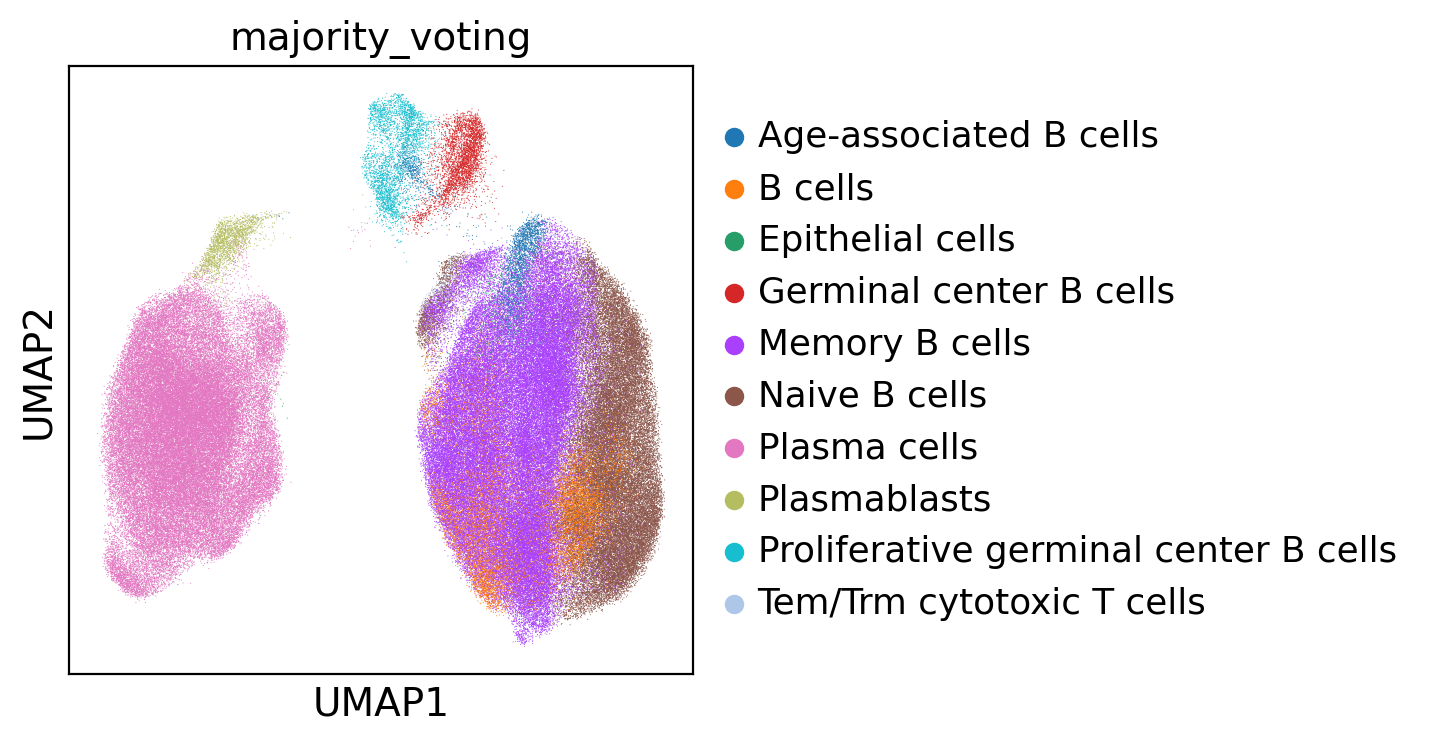

In [10]:
sc.pl.umap(adata_predic, color='majority_voting')

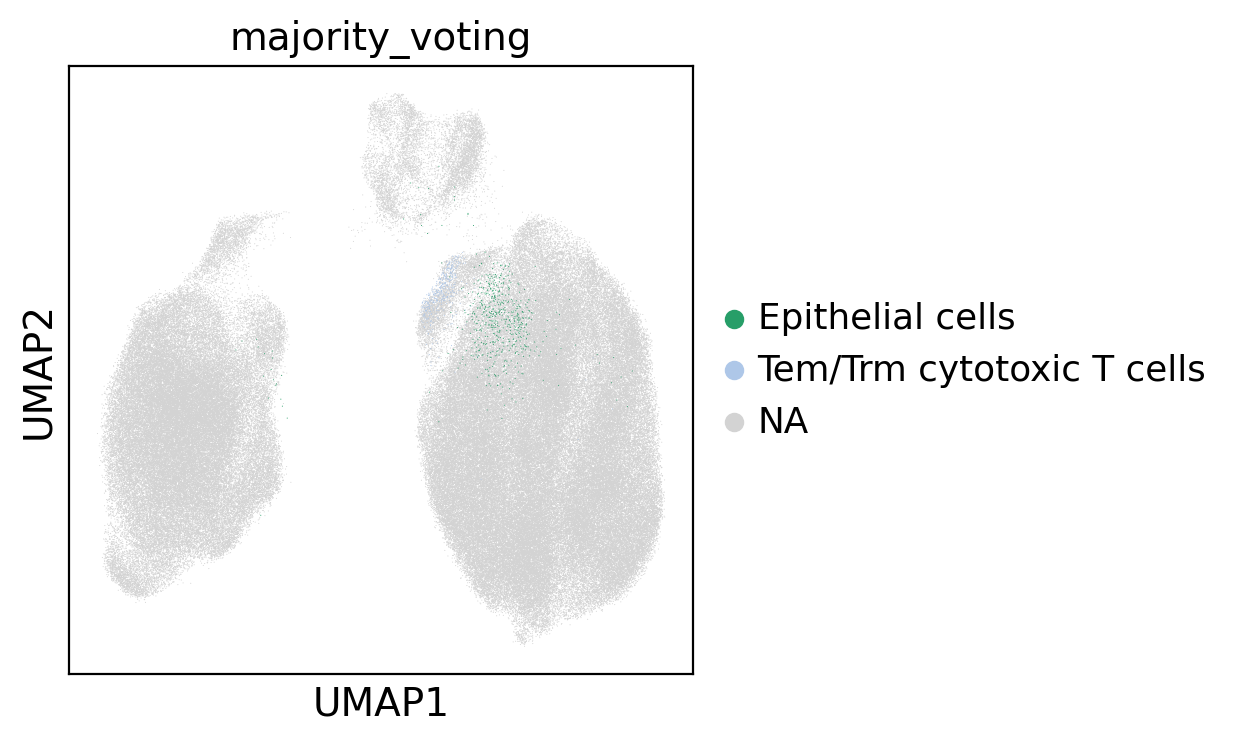

In [11]:
sc.pl.umap(adata_predic, color=['majority_voting'],
           groups=['Tem/Trm cytotoxic T cells','Epithelial cells'])

In [12]:
adata.obs['sub_anno_before']=adata_predic.obs['majority_voting'].copy()

In [13]:
# 'Regulatory T cells' 값을 'Treg'로 변경
adata.obs['sub_anno_before'].replace('Epithelial cells', 'Doublet', inplace=True)
adata.obs['sub_anno_before'].replace('Tem/Trm cytotoxic T cells', 'Doublet', inplace=True)

In [14]:
celltype_rename = {
    'Naive B cells': 'Bn',
    'B cells': 'NR4A2+ Bn',
    'Germinal center B cells': 'Bgc',
    'Proliferative germinal center B cells': 'Cycling Bgc',
    'Memory B cells': 'Bmem',
    'Age-associated B cells': 'ABC',
    'Plasma cells': 'Plasma',
    'Plasmablasts': 'Plasmablast',
}

desired_order = [
    'Bn',
    'NR4A2+ Bn',
    'Bgc',
    'Cycling Bgc',
    'Bmem',
    'ABC',
    'Plasma',
    'Plasmablast',
]

adata.obs['sub_anno']=adata.obs['sub_anno_before'].copy()
adata.obs["sub_anno"] = adata.obs["sub_anno"].astype(str).replace(celltype_rename)

current_vals = adata.obs["sub_anno"].unique().tolist()
ordered_vals = [x for x in desired_order if x in current_vals]
remaining_vals = [x for x in current_vals if x not in ordered_vals]

adata.obs["sub_anno"] = pd.Categorical(
    adata.obs["sub_anno"],
    categories=ordered_vals + remaining_vals,
    ordered=True
)


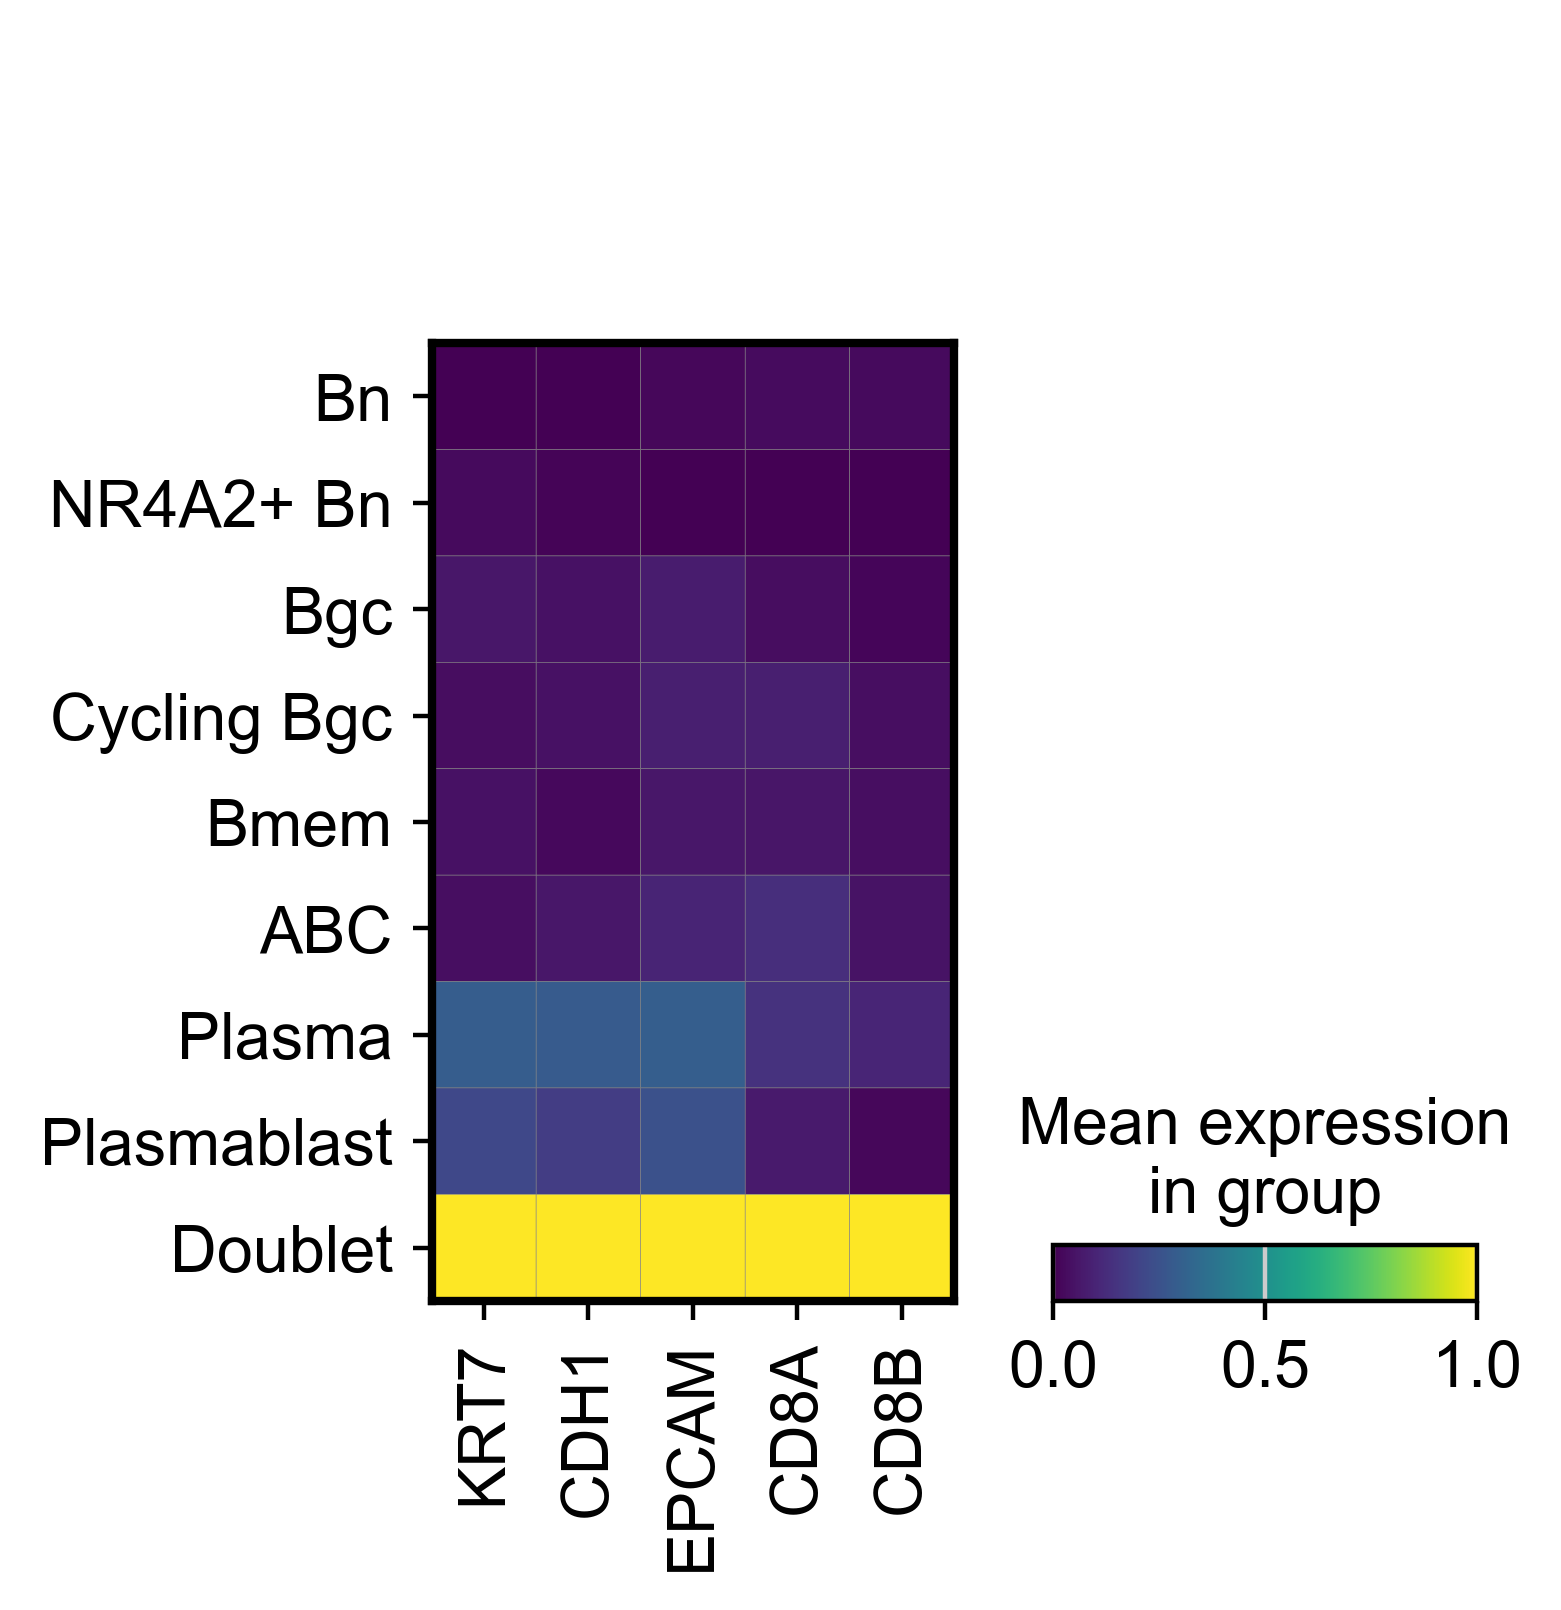

In [15]:
#harmony-batch_key, bbk-'batch_key' - 논문에서 사용한 데이터
sc.pl.matrixplot(adata,groupby='sub_anno',var_names=['KRT7','CDH1','EPCAM','CD8A','CD8B'],standard_scale='var'
                )

In [16]:
adata=adata[~adata.obs['sub_anno_before'].isin(['Doublet'])].copy()

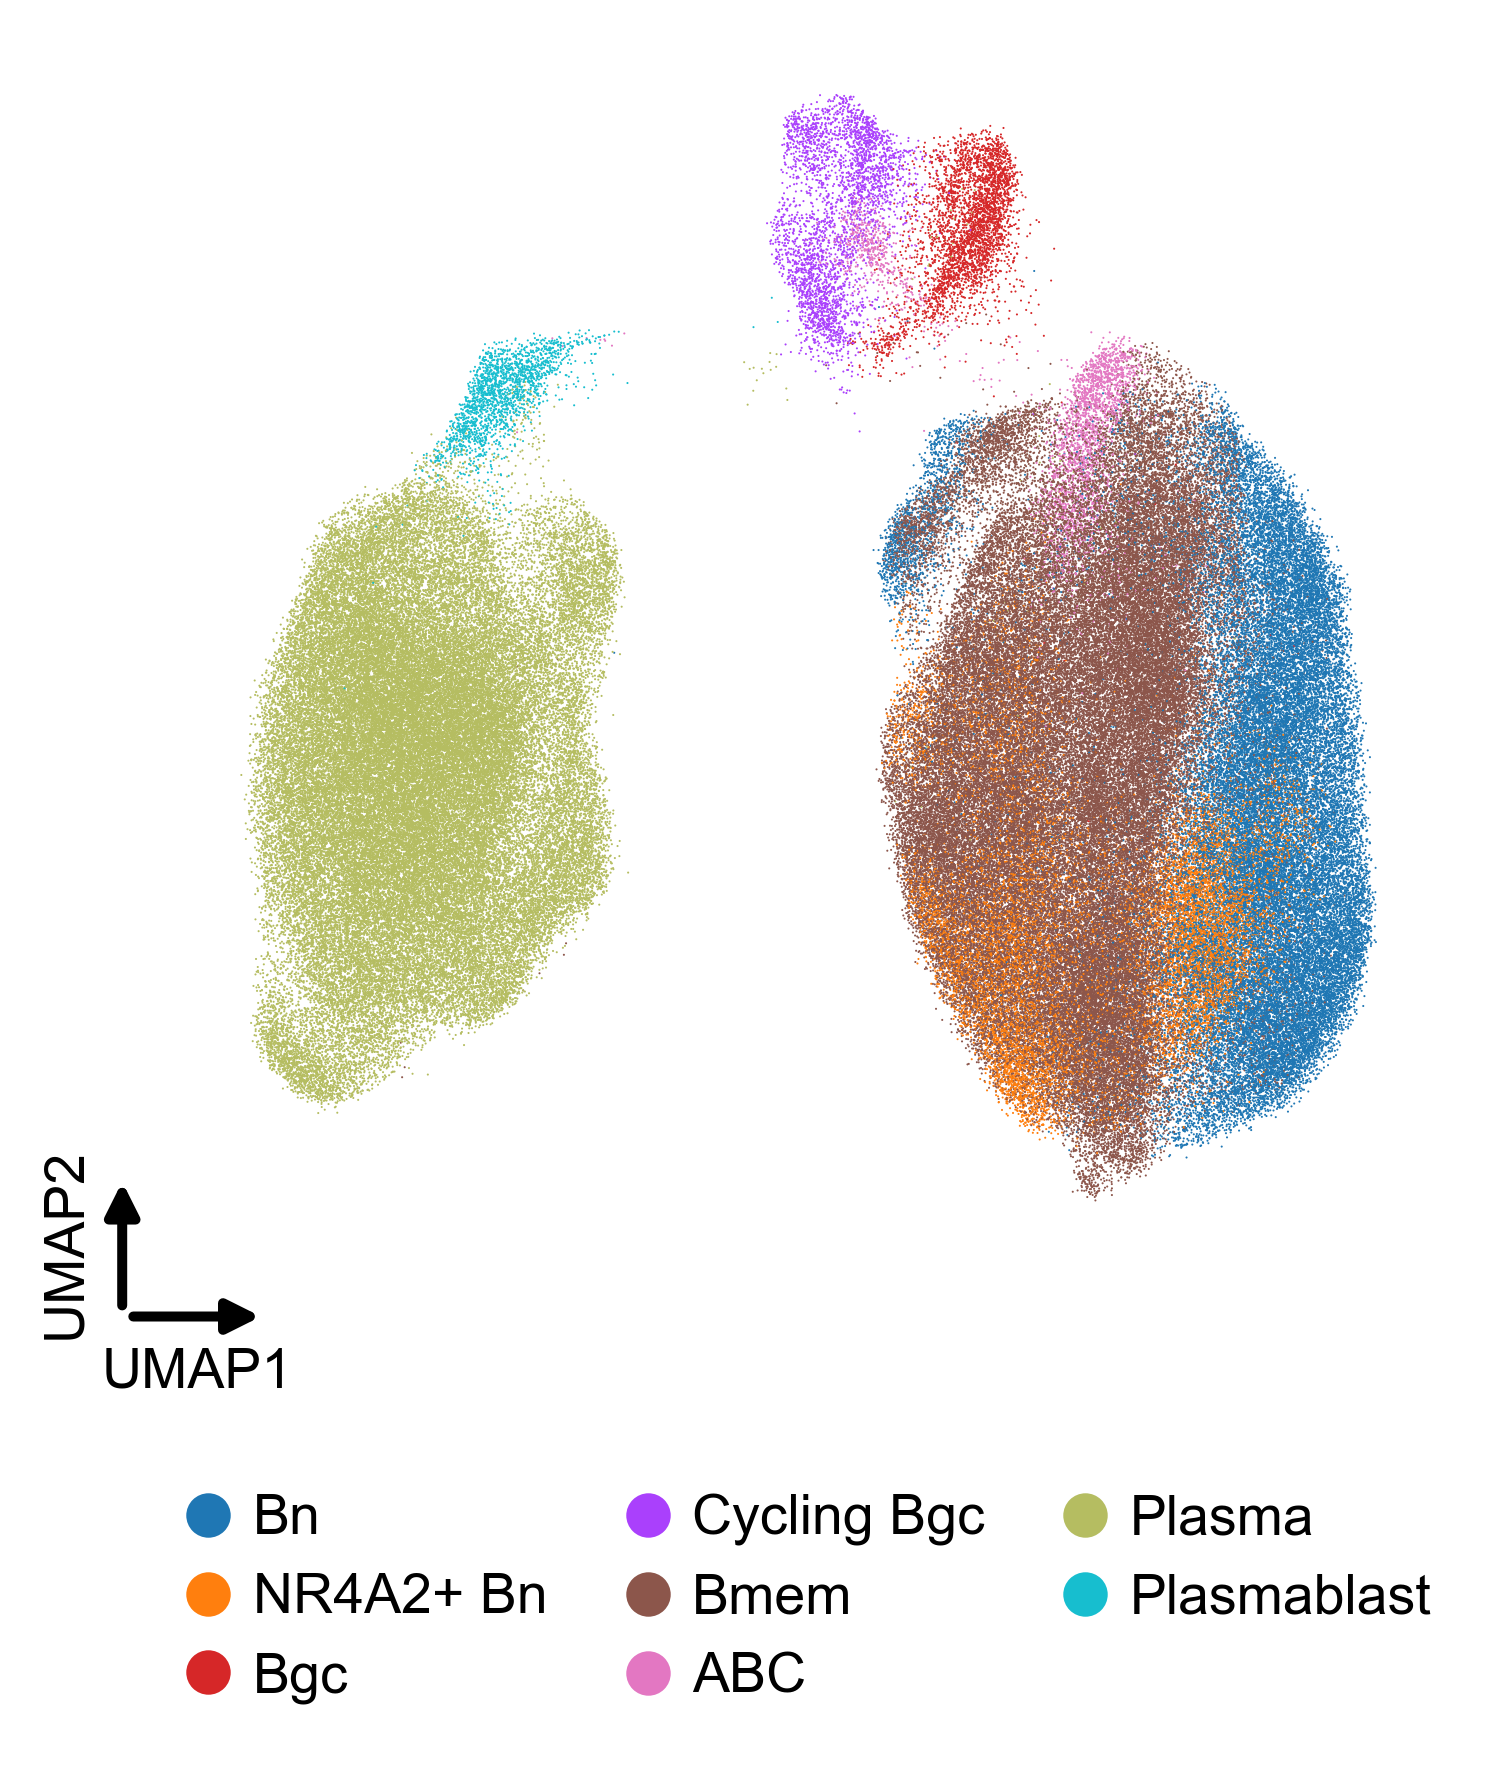

In [17]:
from plotting import umap_with_arrow_axes

# 라벨 → 색 매핑 (이미지의 범례 색)
color_map = {
    'Bn':           '#1f77b4',   
    'NR4A2+ Bn':    '#ff7f0e',   
    'Bgc':          '#d62728',   
    'Cycling Bgc':  '#aa40fc',   
    'Bmem':         '#8c564b',   
    'ABC':          '#e377c2',   
    'Plasma':       '#b5bd61',   
    'Plasmablast':  '#17becf', 
}

cats = adata.obs['sub_anno'].cat.categories
missing = [c for c in cats if c not in color_map]
if missing:
    print('색이 지정되지 않은 카테고리:', missing)   
adata.uns['sub_anno_colors'] = [color_map[c] for c in cats]

umap_with_arrow_axes(adata, savefig="./figures/umap_Bcell.pdf")

In [18]:
sc.tl.rank_genes_groups(adata,groupby='sub_anno',method='wilcoxon')

ranking genes
    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:04:04)


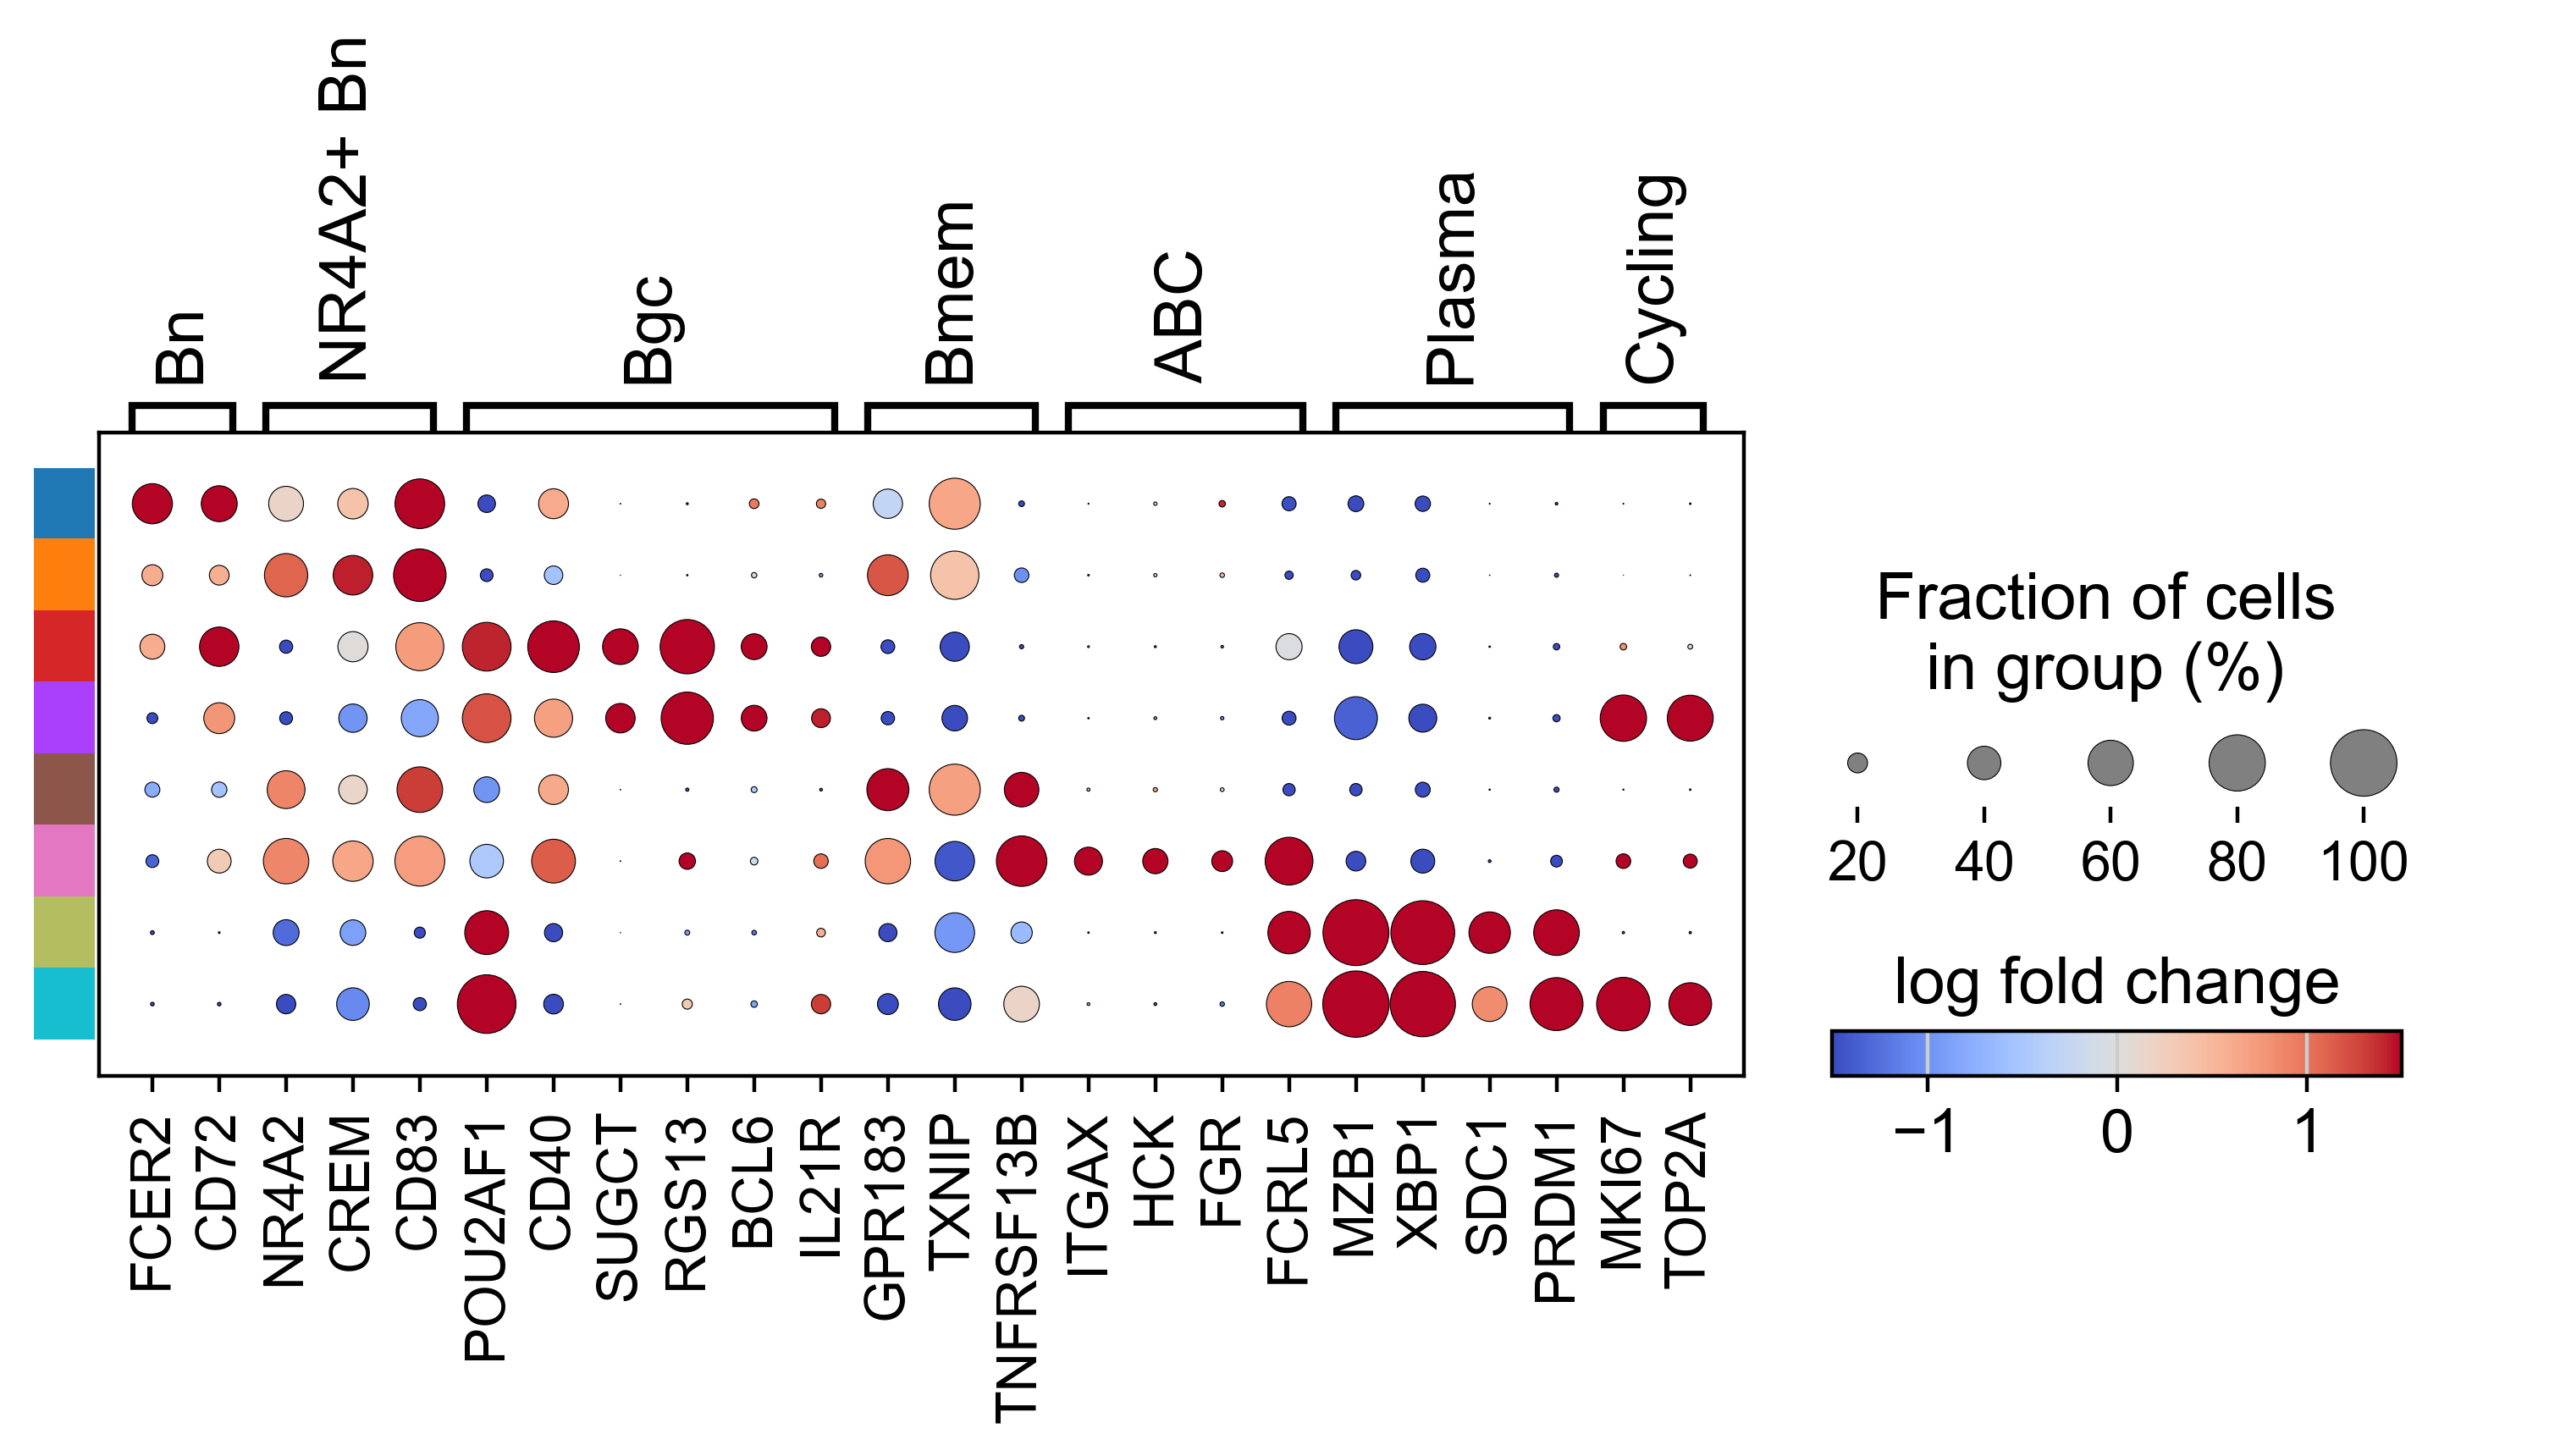

In [19]:
markers = {
    'Bn'       : [ 'FCER2','CD72'],
    'NR4A2+ Bn'   :  ['NR4A2','CREM','CD83'],
    'Bgc'          : ['POU2AF1', 'CD40', 'SUGCT', 'RGS13','BCL6','IL21R'],
    'Bmem'         : ['GPR183','TXNIP','TNFRSF13B'],
    'ABC'         : [ 'ITGAX', 'HCK', 'FGR', 'FCRL5',],
    'Plasma'      : ['MZB1', 'XBP1','SDC1','PRDM1'],
    'Cycling' : ['MKI67', 'TOP2A']}

cats = list(adata.obs["sub_anno"].cat.categories)

dp = sc.pl.rank_genes_groups_dotplot(
    adata,
    groupby="sub_anno",
    categories_order=cats,
    var_names=markers,
    #key="Tcell_DEG",
    cmap="coolwarm",
    dendrogram=False,
    values_to_plot="logfoldchanges",
    vmax=1.5,
    vmin=-1.5,
    figsize=(8, 2.5),
    return_fig=True,
    show=False,
)

axes = dp.get_axes()
ax = axes["mainplot_ax"]
fig = ax.figure

# row annotation color bar
color_map = dict(zip(cats, adata.uns["sub_anno_colors"]))
row_colors = [color_map[c] for c in cats]
rgb = np.array([mcolors.to_rgb(c) for c in row_colors]).reshape(len(cats), 1, 3)

ax.set_yticklabels([])
ax.tick_params(axis="y", length=0)

pos = ax.get_position()
bar_ax = fig.add_axes([pos.x0 - 0.024, pos.y0 - 0.042, 0.0225, pos.height])

# 각 block의 중심을 dot row 중심과 맞춤
bar_ax.imshow(
    rgb,
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    extent=(0, 1, -0.5, len(cats) - 0.5),
)

bar_ax.set_ylim(ax.get_ylim())
bar_ax.set_xlim(0, 1)
bar_ax.set_xticks([])
bar_ax.set_yticks([])

for spine in bar_ax.spines.values():
    spine.set_visible(False)

# dot size legend 조정
size_ax = axes["size_legend_ax"]
pos2 = size_ax.get_position()
size_ax.set_position([pos2.x0, pos2.y0, pos2.width * 1.8, pos2.height])
size_ax.set_title("Fraction of cells\nin group (%)", x=0.4, y=0.6)

coll = size_ax.collections[0]
offsets = coll.get_offsets()

new_x = np.array([0, 0.5, 1.0, 1.5, 2.0])[:offsets.shape[0]]
offsets[:, 0] = new_x
coll.set_offsets(offsets)

ticklabels = [t.get_text() for t in size_ax.get_xticklabels()]
size_ax.set_xticks(new_x)
size_ax.set_xticklabels(ticklabels)
size_ax.set_xlim(new_x.min() - 0.1, new_x.max() + 0.6)

# colorbar 조정
color_ax = axes["color_legend_ax"]
color_ax.set_title("log fold change", fontsize=14)
color_ax.tick_params(labelsize=13)

pos3 = color_ax.get_position()
color_ax.set_position([pos3.x0, pos3.y0, pos3.width * 1.5, pos3.height])

plt.show()

In [ ]:
del adata.obs['sub_anno_before']
adata.write_h5ad('/path/to/h5ad_annotated/_sc_Bcell.h5ad')